# 01 — Exploratory data analysis

Coverage, seam, outliers and the main distributions.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BACKEND = Path.cwd()
if not (BACKEND / "src").exists():
    BACKEND = BACKEND.parent
sys.path.insert(0, str(BACKEND / "src"))
PROCESSED = BACKEND / "data" / "processed"
REPORTS = BACKEND / "reports"


In [2]:
panel = pd.read_csv(PROCESSED / "user_city_month_panel.csv", parse_dates=["date"])
features = pd.read_csv(PROCESSED / "user_city_features.csv")
print("panel", panel.shape, "| features", features.shape)
print("period", panel["date"].min().date(), "->", panel["date"].max().date())
print("observed share", round(float(panel["observed"].mean()), 4))
print("sources", panel["panel_source"].value_counts(dropna=False).to_dict())
display(panel.head(3))

panel (3519, 35) | features (51, 77)
period 2021-01-01 -> 2026-09-01
observed share 0.969
sources {'vahan_export': 2906, 'dashboard_cache': 504, nan: 109}


,city,date,ev_registrations,state_code,year,month,panel_source,tier,rto_codes,observed,...,mkt_comm,total_registrations,transport_registrations,non_transport_registrations,ev_share,commercial_share,mkt_2w_share,mkt_3w_share,mkt_4w_share,non_ev_registrations
0,Agra,2021-01-01,109.0,UP,2021,1,dashboard_cache,tier2,UP-80,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Agra,2021-02-01,99.0,UP,2021,2,dashboard_cache,tier2,UP-80,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Agra,2021-03-01,101.0,UP,2021,3,dashboard_cache,tier2,UP-80,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Coverage by year

In [3]:
coverage = panel.groupby(panel["date"].dt.year).agg(
    city_months=("ev_registrations", "size"),
    observed=("observed", "mean"),
    outliers=("is_outlier", "sum"),
)
display(coverage.round(3))
print("unobserved rows:", int((~panel["observed"]).sum()))
print("cities with no 2021 data:", int(panel[panel["date"].dt.year == 2021].groupby("city")["observed"].sum().eq(0).sum()))

,city_months,observed,outliers
date,,,
2021,612,0.824,5
2022,612,0.998,0
2023,612,1.000,0
2024,612,1.000,4
2025,612,1.000,3
2026,459,1.000,60


unobserved rows: 109
cities with no 2021 data: 9


## National trend and the 2021/2022 seam

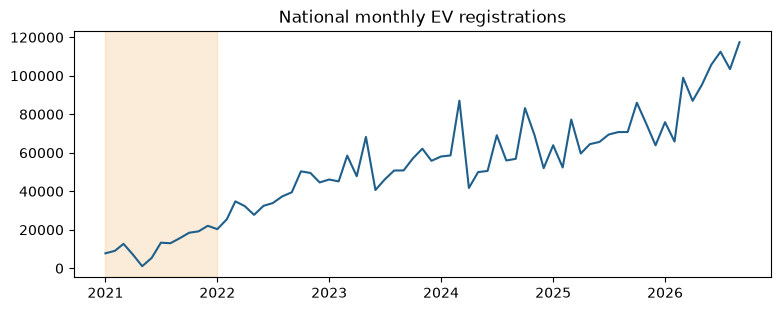

In [4]:
national = panel.groupby("date")["ev_registrations"].sum()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(national.index, national.values, color="#1f5f8b")
ax.axvspan(pd.Timestamp("2021-01-01"), pd.Timestamp("2021-12-31"), color="#e8a33d", alpha=0.2)
ax.set_title("National monthly EV registrations")
plt.show()

In [5]:
seam_path = REPORTS / "seam_2021_2022.csv"
if seam_path.exists():
    seam = pd.read_csv(seam_path)
    print("flag rate:", round(float(seam["seam_flag"].mean()), 3))
    display(seam.nlargest(8, "month_ratio"))
else:
    print("run scripts/diagnose_seam.py first")

flag rate: 0.19


,city,dec_2021,jan_2022,month_ratio,mean_2021,mean_2022,level_ratio,seam_flag
0,Guwahati,14.0,87.0,6.214,10.6,213.8,20.197,True
1,Jabalpur,44.0,97.0,2.205,28.4,219.0,7.707,True
2,Vijayawada,51.0,91.0,1.784,87.5,186.7,2.133,True
3,Kozhikode,56.0,97.0,1.732,38.4,157.2,4.093,True
4,Thiruvananthapuram,60.0,99.0,1.650,33.9,229.4,6.764,True
5,Coimbatore,90.0,140.0,1.556,56.2,199.7,3.550,True
6,Tiruchirappalli,49.0,74.0,1.510,32.2,88.7,2.749,True
7,Aurangabad,142.0,192.0,1.352,72.2,389.3,5.395,False


## Largest cities and missingness

In [6]:
display(features.nlargest(10, "ev_stock")[
    ["city", "ev_stock", "avg_monthly_registrations", "growth_12m", "stations_10km", "effective_public_demand"]
].round(2))
print("missing weighted_ev_stock:", int(features["weighted_ev_stock"].isna().sum()))
print("unverified demographics:", int((~features["demographic_verified"].astype(bool)).sum()))
print("verified policy rows:", int(features.get("policy_verified", pd.Series(False, index=features.index)).sum()))

,city,ev_stock,avg_monthly_registrations,growth_12m,stations_10km,effective_public_demand
0,Bengaluru,439450.0,6368.84,0.46,2297.0,7.55
1,Delhi,393763.0,5706.71,-0.04,601.0,15.12
2,Pune,259189.0,3756.36,0.30,676.0,3.15
3,Hyderabad,173711.0,2517.55,0.64,189.0,54.80
4,Lucknow,137931.0,1999.00,0.25,39.0,304.36
5,Jaipur,104246.0,1510.81,0.46,55.0,113.50
6,Indore,97271.0,1409.72,0.38,43.0,151.23
7,Surat,94760.0,1373.33,0.74,58.0,92.23
8,Ahmedabad,91213.0,1321.93,0.53,99.0,62.80
9,Chennai,89831.0,1301.90,0.76,140.0,30.62


missing weighted_ev_stock: 9
unverified demographics: 0
verified policy rows: 0
